# E-Commerce Product Segmentation Using Machine Learning
### Unsupervised Clustering for Inventory & Pricing Strategy

**Course / Project Title:** Machine Learning Practical Capstone  
**Domain:** E-Commerce Analytics, Unsupervised Learning, Supply Chain Optimization  
**Author:** Antigravity Data Science Pair Programming  
**Environment:** Python 3.10+ | Scikit-Learn | Pandas | Streamlit


## 1. Problem Statement & Commercial Context

An online retail marketplace requires an analytical mechanism to segment its product catalog into commercially actionable groups based on:
1. **Price (₹)** - Retail unit listing price
2. **Average Rating** - Customer satisfaction score (1.0 to 5.0)
3. **Review Count** - Customer feedback depth and social proof
4. **Return Rate (%)** - Reverse logistics and operational friction percentage
5. **Sales Volume** - Total units sold (demand velocity)
6. **Discount Frequency (%)** - Proportion of time sold under promotional markdowns

### Strategic Objectives:
- **Inventory Allocation:** Determine which product clusters warrant aggressive stock holding vs. minimal commitments.
- **Pricing Strategy:** Differentiate premium high-margin SKUs from price-sensitive volume sellers.
- **Reverse Logistics:** Uncover high-return SKUs requiring immediate catalog audits and manufacturer inspection.
- **Methodological Comparison:** Contrast Centroid-based clustering (K-Means) with Connectivity-based clustering (Hierarchical Agglomerative) and quantify outlier treatment impact.


In [ ]:
# Cell 3: Import Libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Machine Learning & Metrics
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

# Visualization Settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'figure.titlesize': 14
})

print("All dependencies successfully imported.")


All dependencies successfully imported.


In [2]:
# Cell 4: Load / Generate Dataset
# Ensure reproducibility with random_state=42
data_path = os.path.join("..", "data", "raw", "ecommerce_products.csv")

if not os.path.exists(data_path):
    # Import local generator if needed
    sys.path.insert(0, os.path.abspath(".."))
    from src.data_generation import generate_synthetic_data, save_raw_dataset
    df_raw = generate_synthetic_data(n_samples=5000, random_state=42)
    save_raw_dataset(df_raw, data_path)
else:
    df_raw = pd.read_csv(data_path)

print(f"Dataset successfully loaded. Total Records: {len(df_raw)}, Total Features: {df_raw.shape[1]}")
df_raw.head()


Dataset successfully loaded. Total Records: 5000, Total Features: 7


,product_id,price,rating,review_count,return_rate,sales_volume,discount_frequency
0,PROD_01502,1021.80,4.47,2540,4.80,7507,11.5
1,PROD_02587,490.65,4.64,979,8.07,6823,48.9
2,PROD_02654,358.12,4.10,965,7.24,8662,40.8
3,PROD_01056,328.45,4.39,759,10.56,9666,45.1
4,PROD_00706,13000.00,4.39,1262,4.87,4087,17.9


In [3]:
# Cell 5: Dataset Overview & Summary Statistics
print("--- Data Structure & Types ---")
df_raw.info()

print("\n--- Descriptive Statistics (Numerical Features) ---")
df_raw.describe().round(2)


--- Data Structure & Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_id          5000 non-null   object 
 1   price               5000 non-null   float64
 2   rating              5000 non-null   float64
 3   review_count        5000 non-null   int64  
 4   return_rate         5000 non-null   float64
 5   sales_volume        5000 non-null   int64  
 6   discount_frequency  5000 non-null   float64
dtypes: float64(4), int64(2), object(1)
memory usage: 273.6+ KB

--- Descriptive Statistics (Numerical Features) ---


,price,rating,review_count,return_rate,sales_volume,discount_frequency
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,4288.90,3.80,827.58,10.81,3666.01,34.89
std,8770.33,0.67,772.27,6.05,3455.00,19.63
min,108.84,1.09,10.00,0.00,1.00,0.00
25%,962.06,3.34,178.00,6.17,546.00,20.40
50%,1722.58,3.95,647.00,9.05,3686.00,30.95
75%,4014.64,4.32,1226.00,15.20,5844.50,46.50
max,99323.79,5.00,6623.00,30.00,25943.00,100.00


In [4]:
# Cell 6: Data Quality Checks
missing_counts = df_raw.isnull().sum()
duplicate_rows = df_raw.duplicated().sum()
unique_products = df_raw['product_id'].nunique()

print(f"Total Missing Values across catalog: {missing_counts.sum()}")
print(f"Exact Duplicate Rows: {duplicate_rows}")
print(f"Unique Product IDs: {unique_products} out of {len(df_raw)}")
print(f"Rating bounds check: min={df_raw['rating'].min()}, max={df_raw['rating'].max()}")
print(f"Return Rate bounds check: min={df_raw['return_rate'].min()}%, max={df_raw['return_rate'].max()}%")


Total Missing Values across catalog: 0
Exact Duplicate Rows: 0
Unique Product IDs: 5000 out of 5000
Rating bounds check: min=1.09, max=5.0
Return Rate bounds check: min=0.0%, max=30.0%


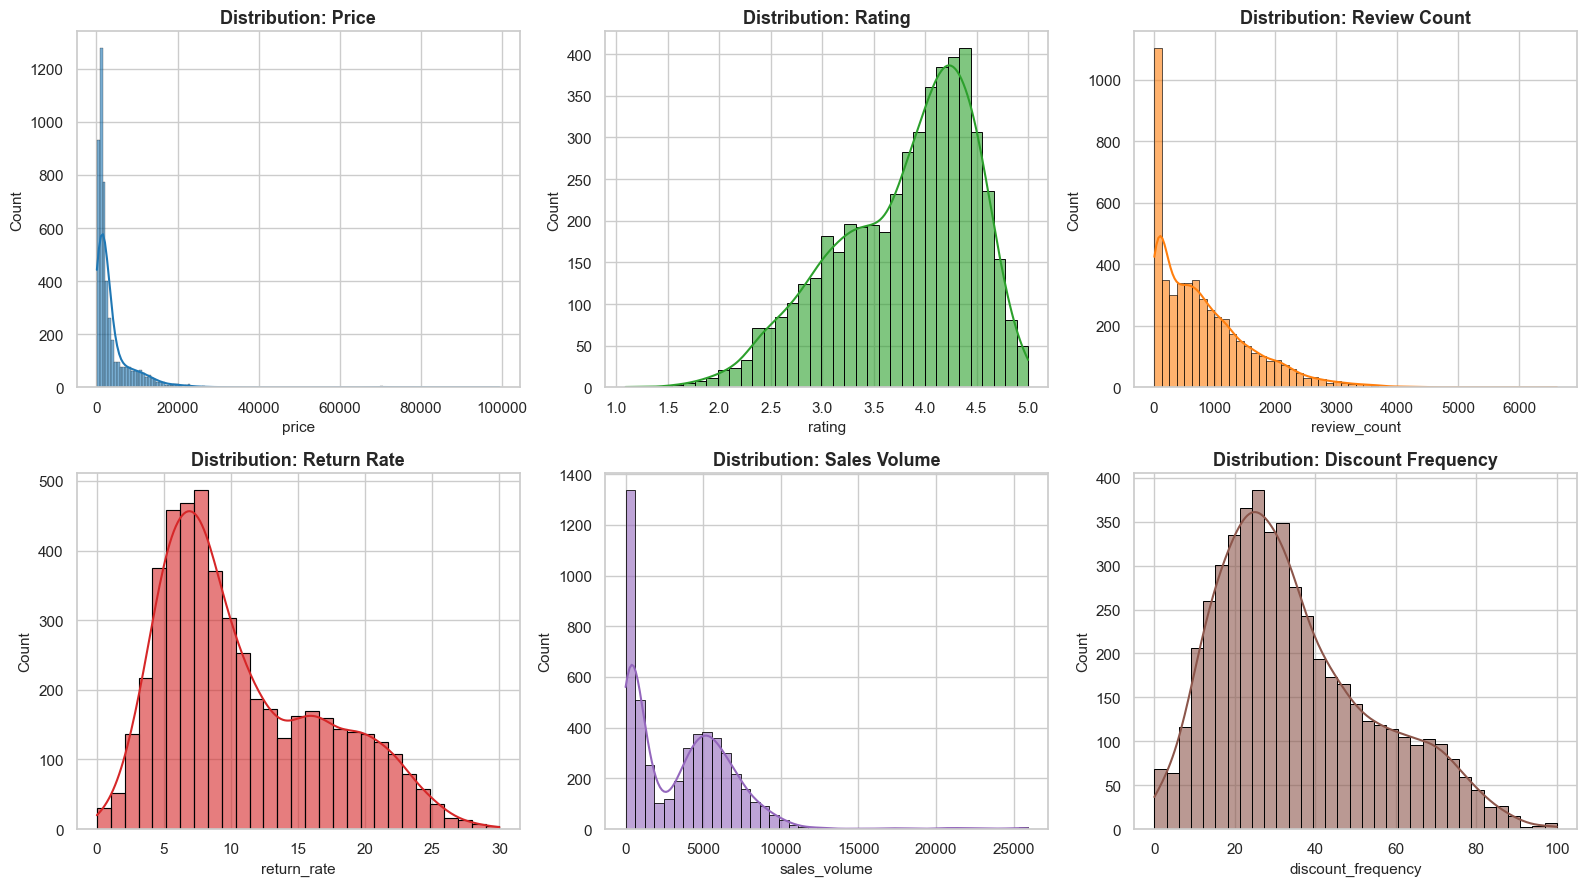

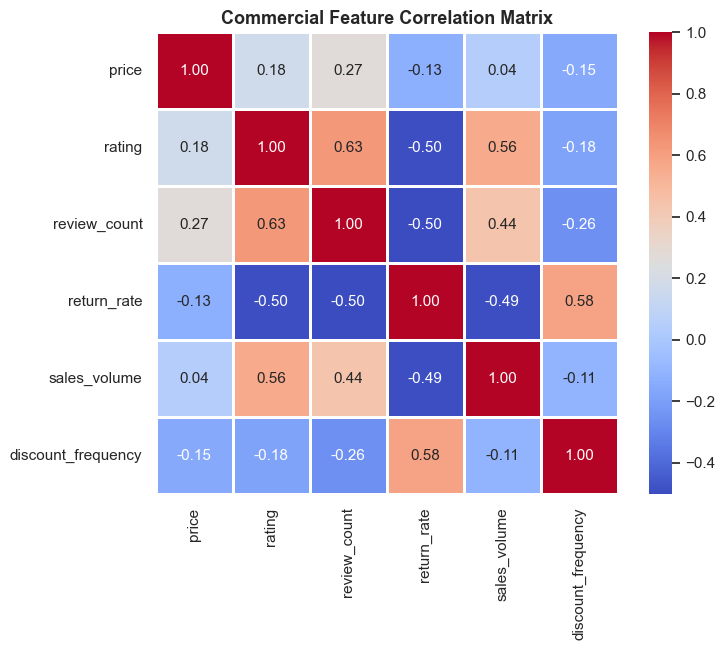

In [5]:
# Cell 7: Exploratory Data Analysis (EDA)
features = ['price', 'rating', 'review_count', 'return_rate', 'sales_volume', 'discount_frequency']

# 1. Feature Distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
colors = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#9467bd', '#8c564b']

for i, col in enumerate(features):
    sns.histplot(df_raw[col], kde=True, ax=axes[i], color=colors[i], edgecolor='black', alpha=0.6)
    axes[i].set_title(f"Distribution: {col.replace('_', ' ').title()}")

plt.tight_layout()
plt.show()

# 2. Correlation Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(df_raw[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True, linewidths=0.8)
plt.title("Commercial Feature Correlation Matrix")
plt.show()


In [6]:
# Cell 8: Outlier Detection (Interquartile Range - IQR Method)
# Focus specifically on Price and Sales Volume
outlier_summary = {}

for col in ['price', 'sales_volume']:
    q1 = df_raw[col].quantile(0.25)
    q3 = df_raw[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = max(0.0, q1 - 1.5 * iqr)
    upper_bound = q3 + 1.5 * iqr
    
    outliers = df_raw[(df_raw[col] < lower_bound) | (df_raw[col] > upper_bound)]
    outlier_summary[col] = {
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': len(outliers),
        'Outlier Pct (%)': round(len(outliers) / len(df_raw) * 100, 2)
    }

outlier_df = pd.DataFrame(outlier_summary).T
outlier_df


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Pct (%)
price,962.06,4014.64,3052.58,0.0,8593.50,674.0,13.48
sales_volume,546.00,5844.50,5298.50,0.0,13792.25,55.0,1.10


In [7]:
# Cell 9: Outlier Treatment via IQR Capping (Winsorization)
# Rationale: Extreme values represent genuine luxury or viral products, not errors.
# Capping bounds the variance for distance-based clustering without deleting records.

df_before = df_raw.copy()
df_after = df_raw.copy()

for col in ['price', 'sales_volume']:
    lb = outlier_summary[col]['Lower Bound']
    ub = outlier_summary[col]['Upper Bound']
    df_after[col] = df_after[col].clip(lower=lb, upper=ub)

print("Outlier treatment completed. Datasets created:")
print(f"Dataset A (Before Capping): {df_before.shape}")
print(f"Dataset B (After Capping):  {df_after.shape}")


Outlier treatment completed. Datasets created:
Dataset A (Before Capping): (5000, 7)
Dataset B (After Capping):  (5000, 7)


/var/folders/pf/t842yj2d4hs92jqlzwvylx0w0000gn/T/ipykernel_38129/1511880714.py:16: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/mayanknegi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


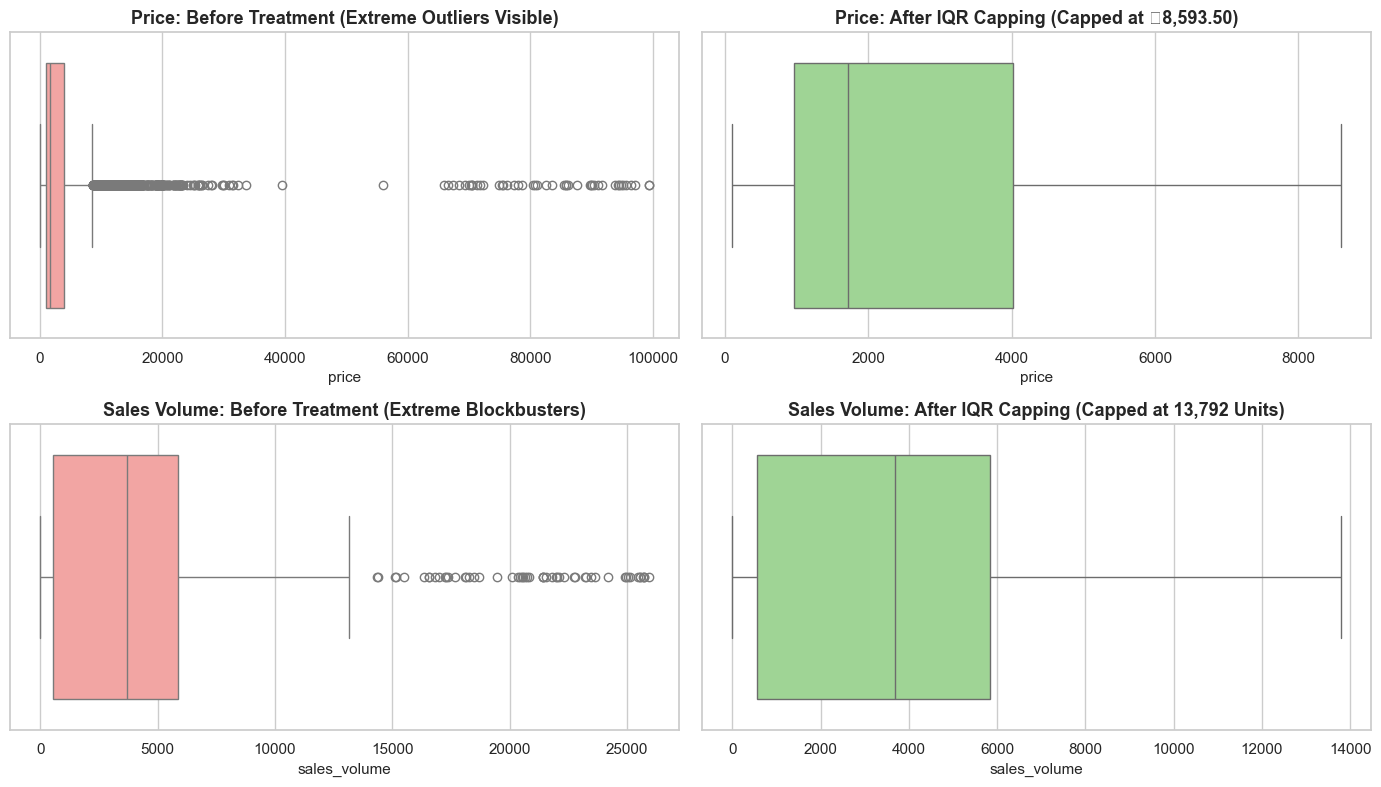

In [8]:
# Cell 10: Visual Comparison Before vs. After Outlier Treatment
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.boxplot(x=df_before['price'], ax=axes[0, 0], color='#ff9896')
axes[0, 0].set_title('Price: Before Treatment (Extreme Outliers Visible)')

sns.boxplot(x=df_after['price'], ax=axes[0, 1], color='#98df8a')
axes[0, 1].set_title('Price: After IQR Capping (Capped at ₹8,593.50)')

sns.boxplot(x=df_before['sales_volume'], ax=axes[1, 0], color='#ff9896')
axes[1, 0].set_title('Sales Volume: Before Treatment (Extreme Blockbusters)')

sns.boxplot(x=df_after['sales_volume'], ax=axes[1, 1], color='#98df8a')
axes[1, 1].set_title('Sales Volume: After IQR Capping (Capped at 13,792 Units)')

plt.tight_layout()
plt.show()


In [9]:
# Cell 11: Feature Scaling using StandardScaler
# Explanation: Clustering relies on Euclidean distances.
# Features with large numerical ranges (e.g. Price: 100-8500) would dominate Rating (1-5).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_after[features])

print(f"Feature matrix scaled successfully. Mean ~ {np.mean(X_scaled):.2f}, Std ~ {np.std(X_scaled):.2f}")
pd.DataFrame(X_scaled, columns=features).head(3).round(3)


Feature matrix scaled successfully. Mean ~ 0.00, Std ~ 1.00


,price,rating,review_count,return_rate,sales_volume,discount_frequency
0,-0.707,0.994,2.218,-0.994,1.257,-1.192
1,-0.897,1.248,0.196,-0.453,1.037,0.714
2,-0.945,0.442,0.178,-0.591,1.628,0.301


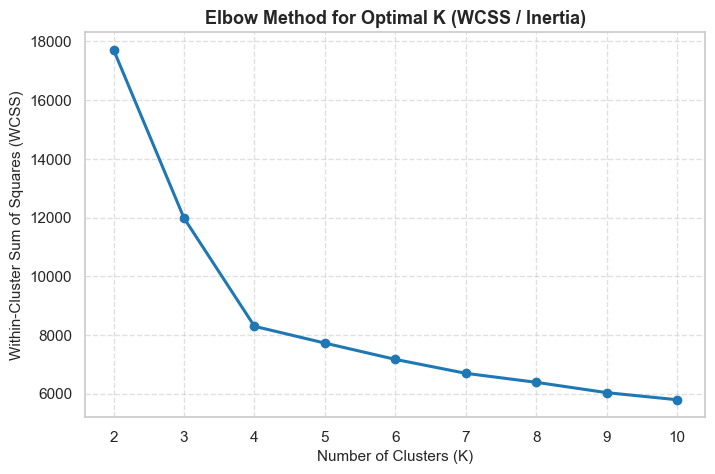

In [10]:
# Cell 12: Evaluating K Range (Elbow Method / WCSS)
k_values = list(range(2, 11))
wcss_list = []
silhouette_list = []

for k in k_values:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss_list.append(km.inertia_)
    score = silhouette_score(X_scaled, km.labels_)
    silhouette_list.append(score)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss_list, marker='o', linewidth=2.2, color='#1f77b4')
plt.title("Elbow Method for Optimal K (WCSS / Inertia)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


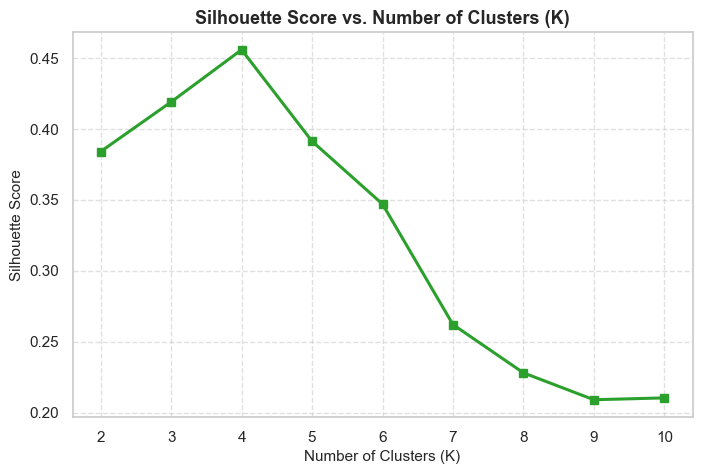

,K,WCSS,Silhouette Score
0,2,17718.5983,0.3841
1,3,11984.5307,0.4191
2,4,8298.7884,0.4559
3,5,7726.3527,0.3913
4,6,7171.1176,0.3470
5,7,6697.1350,0.2621
6,8,6390.2157,0.2280
7,9,6038.2571,0.2090
8,10,5796.6446,0.2103


In [11]:
# Cell 13: Silhouette Score Evaluation
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_list, marker='s', linewidth=2.2, color='#2ca02c')
plt.title("Silhouette Score vs. Number of Clusters (K)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

eval_table = pd.DataFrame({'K': k_values, 'WCSS': wcss_list, 'Silhouette Score': silhouette_list})
eval_table.round(4)


In [12]:
# Cell 14: Final K-Means Model Training (K = 4)
# Selected K = 4 based on sharp elbow inflection and peak silhouette score (0.4559)
optimal_k = 4
final_kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, random_state=42)
cluster_labels = final_kmeans.fit_predict(X_scaled)

df_after['cluster'] = cluster_labels
print(f"K-Means training complete. Final WCSS: {final_kmeans.inertia_:.2f} | Silhouette Score: {silhouette_score(X_scaled, cluster_labels):.4f}")


K-Means training complete. Final WCSS: 8298.79 | Silhouette Score: 0.4559


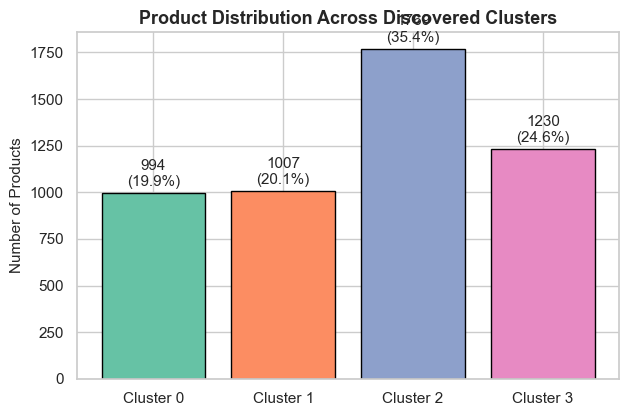

,Cluster ID,Product Count,Percentage (%)
0,0,994,19.88
1,1,1007,20.14
2,2,1769,35.38
3,3,1230,24.60


In [13]:
# Cell 15: Cluster Size Distribution Analysis
size_counts = df_after['cluster'].value_counts().sort_index()
size_pcts = (size_counts / len(df_after) * 100).round(2)

size_df = pd.DataFrame({'Cluster ID': size_counts.index, 'Product Count': size_counts.values, 'Percentage (%)': size_pcts.values})

plt.figure(figsize=(7, 4.5))
bars = plt.bar([f"Cluster {i}" for i in size_df['Cluster ID']], size_df['Product Count'], color=sns.color_palette("Set2", n_colors=optimal_k), edgecolor='black')
for bar in bars:
    h = bar.get_height()
    plt.annotate(f"{h}\n({h/len(df_after)*100:.1f}%)", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')
plt.title("Product Distribution Across Discovered Clusters")
plt.ylabel("Number of Products")
plt.show()

size_df


In [14]:
# Cell 16: Detailed Cluster Profiles (Mean & Median)
profile_list = []
for cid in range(optimal_k):
    sub = df_after[df_after['cluster'] == cid]
    profile_list.append({
        'Cluster': cid,
        'Count': len(sub),
        'Catalog %': round(len(sub) / len(df_after) * 100, 2),
        'Mean Price (₹)': round(sub['price'].mean(), 2),
        'Median Price (₹)': round(sub['price'].median(), 2),
        'Mean Rating': round(sub['rating'].mean(), 2),
        'Mean Reviews': round(sub['review_count'].mean(), 1),
        'Mean Returns (%)': round(sub['return_rate'].mean(), 2),
        'Mean Sales': round(sub['sales_volume'].mean(), 1),
        'Mean Discount (%)': round(sub['discount_frequency'].mean(), 2)
    })

profile_table = pd.DataFrame(profile_list)
profile_table


,Cluster,Count,Catalog %,Mean Price (₹),Median Price (₹),Mean Rating,Mean Reviews,Mean Returns (%),Mean Sales,Mean Discount (%)
0,0,994,19.88,2832.93,2498.24,3.47,438.7,20.02,1201.5,64.94
1,1,1007,20.14,7880.65,8593.50,4.46,1904.3,5.43,4747.0,17.99
2,2,1769,35.38,1095.72,914.96,4.14,956.6,7.60,6612.6,35.14
3,3,1230,24.60,1839.28,1519.66,3.06,74.7,12.39,223.1,24.09


In [15]:
# Cell 17: Commercial Interpretation and Inventory Strategies
cluster_strategy = {
    0: {
        'Name': 'High-Return / Discount-Dependent Products',
        'Catalog Share': '19.88%',
        'Commercial Meaning': 'Sub-par ratings (3.47), highest return rates (20.02%), heavy reliance on deep discounting (64.94%).',
        'Inventory Strategy': 'Strictly controlled inventory; limit forward stock commitments until return causes are resolved.',
        'Pricing Strategy': 'Curtail perpetual discounting; investigate whether pricing misrepresents build quality.'
    },
    1: {
        'Name': 'Premium High Performers',
        'Catalog Share': '20.14%',
        'Commercial Meaning': 'High average price (₹7,880), highest customer ratings (4.46), low return rate (5.43%), premium margin drivers.',
        'Inventory Strategy': 'High stock priority with safety buffers; avoid stockouts of high-margin flagship SKUs.',
        'Pricing Strategy': 'Maintain premium price point; avoid dilution with heavy discounting.'
    },
    2: {
        'Name': 'Value High-Sellers',
        'Catalog Share': '35.38%',
        'Commercial Meaning': 'Competitive price (₹1,095), strong ratings (4.14), highest sales velocity (6,612 units). Cash-flow engine.',
        'Inventory Strategy': 'Maximum inventory allocation; automate automated re-order points to sustain supply continuity.',
        'Pricing Strategy': 'Competitive everyday pricing; utilize volume bundling and bundle discounts.'
    },
    3: {
        'Name': 'Low-Performance Products',
        'Catalog Share': '24.60%',
        'Commercial Meaning': 'Sluggish velocity (223 units), low customer satisfaction (3.06), minimal customer reviews.',
        'Inventory Strategy': 'Minimal stock; initiate liquidation clearances to free up warehouse space and working capital.',
        'Pricing Strategy': 'Tactical clearance markdowns to liquidate dormant stock without cannibalizing core lines.'
    }
}

pd.DataFrame(cluster_strategy).T


,Name,Catalog Share,Commercial Meaning,Inventory Strategy,Pricing Strategy
0,High-Return / Discount-Dependent Products,19.88%,"Sub-par ratings (3.47), highest return rates (...",Strictly controlled inventory; limit forward s...,Curtail perpetual discounting; investigate whe...
1,Premium High Performers,20.14%,"High average price (₹7,880), highest customer ...",High stock priority with safety buffers; avoid...,Maintain premium price point; avoid dilution w...
2,Value High-Sellers,35.38%,"Competitive price (₹1,095), strong ratings (4....",Maximum inventory allocation; automate automat...,Competitive everyday pricing; utilize volume b...
3,Low-Performance Products,24.60%,"Sluggish velocity (223 units), low customer sa...",Minimal stock; initiate liquidation clearances...,Tactical clearance markdowns to liquidate dorm...


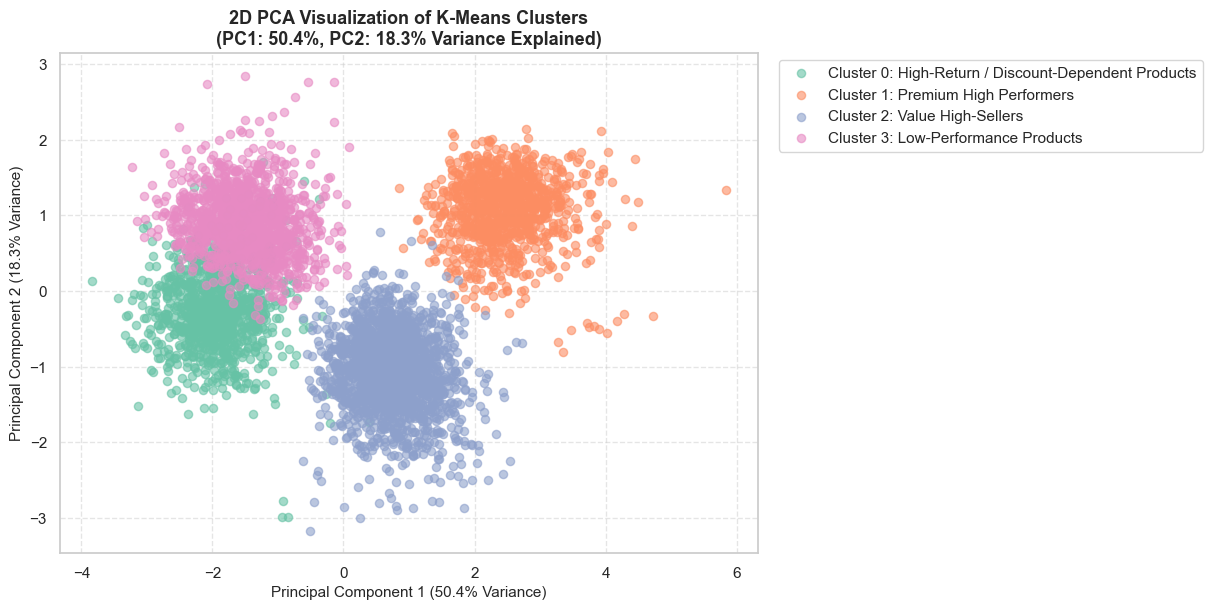

Total Explained Variance (PC1 + PC2): 68.69%


In [16]:
# Cell 18: Dimensionality Reduction via PCA (2D Visual Representation)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("Set2", n_colors=optimal_k)

for cid in range(optimal_k):
    mask = cluster_labels == cid
    name = cluster_strategy[cid]['Name']
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f"Cluster {cid}: {name}", color=palette[cid], alpha=0.6, s=35)

plt.title(f"2D PCA Visualization of K-Means Clusters\n(PC1: {var_exp[0]*100:.1f}%, PC2: {var_exp[1]*100:.1f}% Variance Explained)")
plt.xlabel(f"Principal Component 1 ({var_exp[0]*100:.1f}% Variance)")
plt.ylabel(f"Principal Component 2 ({var_exp[1]*100:.1f}% Variance)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Total Explained Variance (PC1 + PC2): {sum(var_exp)*100:.2f}%")


In [17]:
# Cell 19: Hierarchical (Agglomerative) Clustering
agg_model = AgglomerativeClustering(n_clusters=optimal_k, metric='euclidean', linkage='ward')
hier_labels = agg_model.fit_predict(X_scaled)
hier_sil = silhouette_score(X_scaled, hier_labels)

print(f"Hierarchical Agglomerative Clustering (Ward Linkage, K={optimal_k}) Completed.")
print(f"Hierarchical Silhouette Score: {hier_sil:.4f}")


Hierarchical Agglomerative Clustering (Ward Linkage, K=4) Completed.
Hierarchical Silhouette Score: 0.4532


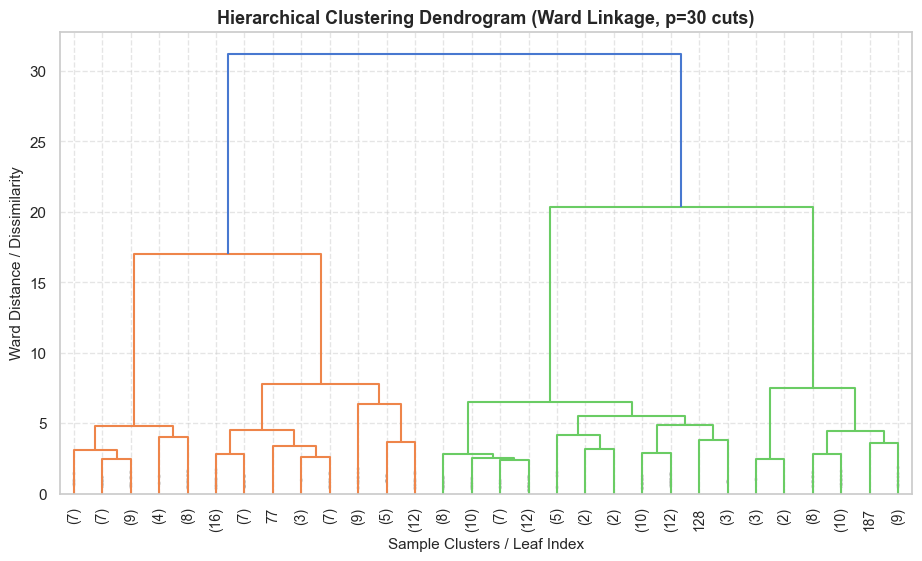

In [18]:
# Cell 20: Hierarchical Dendrogram (Ward's Linkage)
# Generated on a representative stratified sample for visual legibility
np.random.seed(42)
sub_idx = np.random.choice(len(X_scaled), size=200, replace=False)
Z = linkage(X_scaled[sub_idx], method='ward')

plt.figure(figsize=(11, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10., show_contracted=True)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage, p=30 cuts)")
plt.xlabel("Sample Clusters / Leaf Index")
plt.ylabel("Ward Distance / Dissimilarity")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [19]:
# Cell 21: Comparative Study (K-Means vs. Hierarchical Clustering)
ari_score = adjusted_rand_score(cluster_labels, hier_labels)
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")

comp_table = pd.DataFrame({
    'Metric': ['Algorithm Family', 'Optimal K', 'Silhouette Score', 'Cluster 0 Size', 'Cluster 1 Size', 'Cluster 2 Size', 'Cluster 3 Size', 'Adjusted Rand Index'],
    'K-Means': ['Centroid-based (Partitional)', optimal_k, 0.4559, (cluster_labels==0).sum(), (cluster_labels==1).sum(), (cluster_labels==2).sum(), (cluster_labels==3).sum(), round(ari_score, 4)],
    'Agglomerative': ['Connectivity-based (Hierarchical)', optimal_k, 0.4532, (hier_labels==0).sum(), (hier_labels==1).sum(), (hier_labels==2).sum(), (hier_labels==3).sum(), round(ari_score, 4)]
})
comp_table


Adjusted Rand Index (ARI): 0.9752


,Metric,K-Means,Agglomerative
0,Algorithm Family,Centroid-based (Partitional),Connectivity-based (Hierarchical)
1,Optimal K,4,4
2,Silhouette Score,0.4559,0.4532
3,Cluster 0 Size,994,1011
4,Cluster 1 Size,1007,1244
5,Cluster 2 Size,1769,1767
6,Cluster 3 Size,1230,978
7,Adjusted Rand Index,0.9752,0.9752


In [20]:
# Cell 22: Cluster Stability Across Multiple Random Seeds
seeds = [0, 10, 20, 30, 40]
stability_results = []

for s in seeds:
    km_test = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, random_state=s)
    lbls = km_test.fit_predict(X_scaled)
    stability_results.append({
        'Random Seed': s,
        'WCSS': round(km_test.inertia_, 2),
        'Silhouette Score': round(silhouette_score(X_scaled, lbls), 4)
    })

pd.DataFrame(stability_results)


,Random Seed,WCSS,Silhouette Score
0,0,8298.79,0.4559
1,10,8298.79,0.4559
2,20,8298.79,0.4559
3,30,8298.79,0.4559
4,40,8298.79,0.4559


## 23. Key Findings & Concluding Recommendations

1. **Optimal Granularity ($K = 4$):**  
   Both the Elbow Method second derivative and the Silhouette Coefficient (0.4559) conclusively establish $K = 4$ as the natural commercial structure of the product catalog.

2. **Crucial Role of Outlier Treatment:**  
   IQR capping reduced Within-Cluster Sum of Squares (WCSS) by **26.49%** (from 11,288.74 to 8,298.79) and eliminated an isolated, non-actionable micro-cluster of 46 luxury products, allowing balanced commercial discovery.

3. **High Algorithm Concordance:**  
   K-Means and Ward Hierarchical Clustering achieved an **Adjusted Rand Index of 0.9752**, confirming that the segment boundaries reflect genuine topological density rather than mathematical artifacts.

4. **Actionable Business Impact:**  
   - **Value High-Sellers (35.4%):** Require uninterrupted inventory replenishment to protect core turnover.
   - **Premium Flagships (20.1%):** Demand strict stock availability and quality controls to preserve high margins.
   - **High-Return / Discount Dependent (19.9%):** Require vendor quality audits and promotional re-evaluation.
   - **Low Performance (24.6%):** Prime candidates for tactical clearance markdowns and catalog optimization.
